In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the Concrete Compressive Strength dataset
df = pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1030, 9)

Column Names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']

First 5 Rows:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Step 1: Clean the dataset
df_clean = df.dropna().drop_duplicates().copy()

# Step 2: Separate features and target
X = df_clean.drop(columns=['concrete_compressive_strength'])
y = df_clean['concrete_compressive_strength']

# Step 3: Split data (80% training, 20% testing)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Polynomial Features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_raw)
X_test_poly = poly.transform(X_test_raw)

# Step 5: Feature Scaling
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Step 6: Target Scaling
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(
    y_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = scaler_y.transform(
    y_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Display results
print("Original Rows:", len(df))
print("Clean Rows:", len(df_clean))
print("Training Samples:", X_train_scaled.shape[0])
print("Testing Samples:", X_test_scaled.shape[0])
print("Polynomial Features:", X_train_scaled.shape[1])
print("Training Target Mean:", round(y_train.mean(), 4))


Original Rows: 1030
Clean Rows: 1005
Training Samples: 804
Testing Samples: 201
Polynomial Features: 44
Training Target Mean: 0.0


In [4]:

# RMSprop Optimizer from Scratch

# Add bias column (x0 = 1)
X_train_rms = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Initialize parameters
m_rms, n_rms = X_train_rms.shape
theta_rms = np.zeros(n_rms)

# Hyperparameters
learning_rate_rms = 0.0005
epochs_rms = 2000
batch_size_rms = 32
beta_rms = 0.9
epsilon = 1e-8

# Initialize squared gradient moving average
s_rms = np.zeros(n_rms)

# Random generator
rng_rms = np.random.default_rng(42)

# Store cost values
cost_history_rms = []

# Calculate initial cost
initial_cost_rms = np.mean(y_train ** 2) / 2

# RMSprop Training
for epoch in range(epochs_rms):

    # Shuffle training examples
    indices = rng_rms.permutation(m_rms)

    # Process mini-batches
    for start in range(0, m_rms, batch_size_rms):

        batch_indices = indices[start:start + batch_size_rms]

        X_batch = X_train_rms[batch_indices]
        y_batch = y_train[batch_indices]

        # Calculate predictions
        predictions = X_batch @ theta_rms

        # Calculate errors
        errors = predictions - y_batch

        # Calculate gradients
        gradients = (X_batch.T @ errors) / len(batch_indices)

        # Update moving average of squared gradients
        s_rms = (
            beta_rms * s_rms
            + (1 - beta_rms) * (gradients ** 2)
        )

        # RMSprop parameter update
        theta_rms -= (
            learning_rate_rms * gradients
            / (np.sqrt(s_rms) + epsilon)
        )

    # Calculate full training cost
    full_predictions = X_train_rms @ theta_rms
    cost = np.mean((full_predictions - y_train) ** 2) / 2

    cost_history_rms.append(cost)

# Display results
print("Optimizer: RMSprop")
print("Learning Rate:", learning_rate_rms)
print("Epochs:", epochs_rms)
print("Batch Size:", batch_size_rms)
print("Beta:", beta_rms)
print("Number of Parameters:", n_rms)
print("Initial Cost:", round(initial_cost_rms, 6))
print("Final Cost:", round(cost_history_rms[-1], 6))


Optimizer: RMSprop
Learning Rate: 0.0005
Epochs: 2000
Batch Size: 32
Beta: 0.9
Number of Parameters: 45
Initial Cost: 0.5
Final Cost: 0.105167


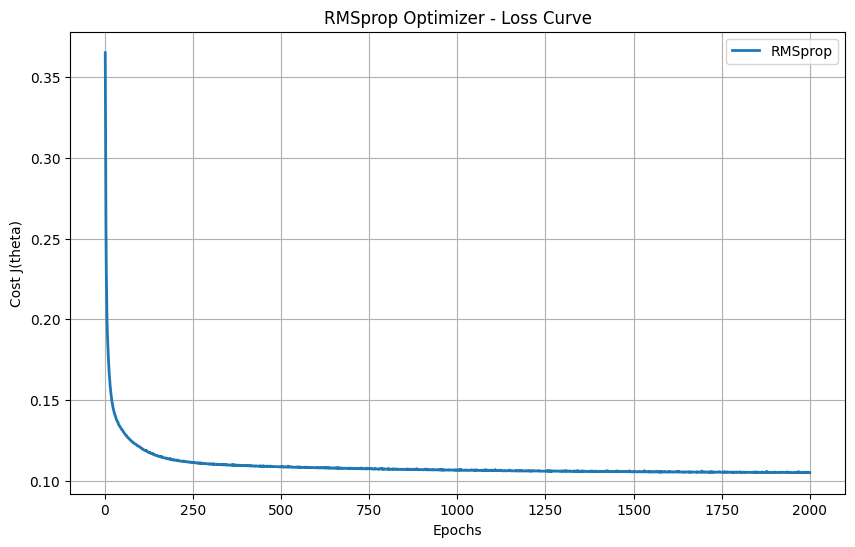

In [5]:

# Plot RMSprop Loss Curve

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_rms + 1),
    cost_history_rms,
    label='RMSprop',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('RMSprop Optimizer - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [6]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Prepare test data
X_test_rms = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Make predictions
y_pred_scaled_rms = X_test_rms @ theta_rms

# Convert predictions to original scale
y_pred_rms = scaler_y.inverse_transform(
    y_pred_scaled_rms.reshape(-1, 1)
).ravel()

# Actual test values
y_actual = y_test_raw.to_numpy()

# Calculate evaluation metrics
mse_rms = mean_squared_error(y_actual, y_pred_rms)
rmse_rms = np.sqrt(mse_rms)
mae_rms = mean_absolute_error(y_actual, y_pred_rms)
r2_rms = r2_score(y_actual, y_pred_rms)

print("RMSprop - Test Results")
print("-------------------------")
print("MSE:", round(mse_rms, 4))
print("RMSE:", round(rmse_rms, 4))
print("MAE:", round(mae_rms, 4))
print("R2 Score:", round(r2_rms, 4))


RMSprop - Test Results
-------------------------
MSE: 68.582
RMSE: 8.2814
MAE: 6.0841
R2 Score: 0.7701


In [7]:

# RMSprop with Momentum from Scratch

theta_rms_momentum = np.zeros(n_rms)

# Initialize moving averages
s_rms_momentum = np.zeros(n_rms)
velocity_rms = np.zeros(n_rms)

# Hyperparameters
momentum = 0.9
rng_rms_momentum = np.random.default_rng(42)

cost_history_rms_momentum = []

# Training
for epoch in range(epochs_rms):

    indices = rng_rms_momentum.permutation(m_rms)

    for start in range(0, m_rms, batch_size_rms):

        batch_indices = indices[start:start + batch_size_rms]

        X_batch = X_train_rms[batch_indices]
        y_batch = y_train[batch_indices]

        predictions = X_batch @ theta_rms_momentum
        errors = predictions - y_batch

        gradients = (X_batch.T @ errors) / len(batch_indices)

        # RMSprop squared gradient average
        s_rms_momentum = (
            beta_rms * s_rms_momentum
            + (1 - beta_rms) * gradients**2
        )

        # Adaptive gradient
        adaptive_gradient = gradients / (
            np.sqrt(s_rms_momentum) + epsilon
        )

        # Momentum (normalized moving average)
        velocity_rms = (
            momentum * velocity_rms
            + (1 - momentum) * adaptive_gradient
        )

        # Update weights
        theta_rms_momentum -= learning_rate_rms * velocity_rms

    # Calculate training loss
    predictions = X_train_rms @ theta_rms_momentum
    cost = np.mean((predictions - y_train)**2) / 2

    cost_history_rms_momentum.append(cost)

# Test predictions
X_test_rms = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

y_pred_mom_scaled = X_test_rms @ theta_rms_momentum

y_pred_mom = scaler_y.inverse_transform(
    y_pred_mom_scaled.reshape(-1, 1)
).ravel()

# Evaluation
rmse_rms_momentum = np.sqrt(
    mean_squared_error(y_actual, y_pred_mom)
)

r2_rms_momentum = r2_score(y_actual, y_pred_mom)

# Comparison
print("RMSprop vs RMSprop with Momentum")
print("--------------------------------")
print("RMSprop Final Cost:",
      round(cost_history_rms[-1], 6))
print("Momentum Final Cost:",
      round(cost_history_rms_momentum[-1], 6))

print("RMSprop Test RMSE:",
      round(rmse_rms, 4))
print("Momentum Test RMSE:",
      round(rmse_rms_momentum, 4))

print("RMSprop Test R2:",
      round(r2_rms, 4))
print("Momentum Test R2:",
      round(r2_rms_momentum, 4))


RMSprop vs RMSprop with Momentum
--------------------------------
RMSprop Final Cost: 0.105167
Momentum Final Cost: 0.105139
RMSprop Test RMSE: 8.2814
Momentum Test RMSE: 8.2988
RMSprop Test R2: 0.7701
Momentum Test R2: 0.7691


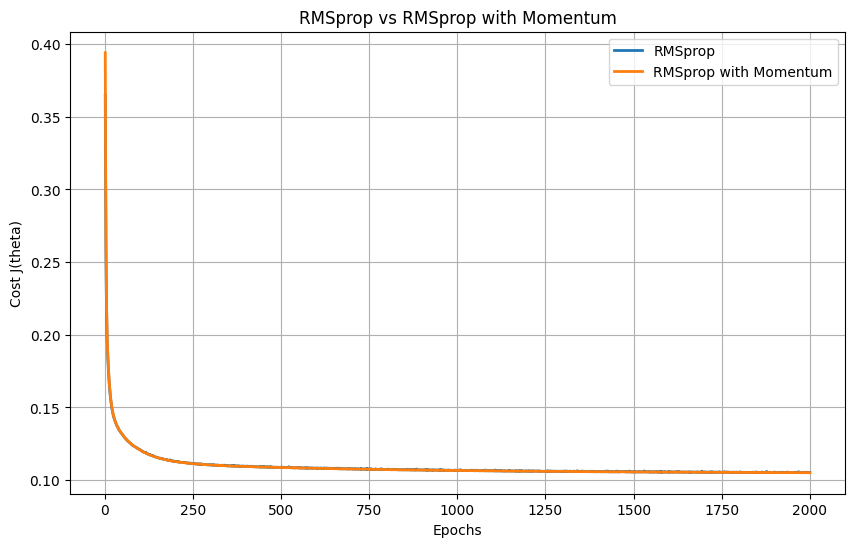

In [8]:

# Compare RMSprop and RMSprop with Momentum

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_rms + 1),
    cost_history_rms,
    label='RMSprop',
    linewidth=2
)

plt.plot(
    range(1, epochs_rms + 1),
    cost_history_rms_momentum,
    label='RMSprop with Momentum',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('RMSprop vs RMSprop with Momentum')
plt.legend()
plt.grid(True)
plt.show()



## Results and Discussion

In this experiment, Polynomial Regression (degree = 2) was trained using RMSprop and RMSprop with Momentum.

### Experimental Results

| Metric | RMSprop | RMSprop with Momentum |
|---|---|---|
| Final Training Cost | 0.105167 | 0.105139 |
| Test RMSE | 8.2814 | 8.2988 |
| Test R² | 0.7701 | 0.7691 |

### Discussion

RMSprop successfully optimized the Polynomial Regression model using an adaptive learning rate and a moving average of squared gradients.

Momentum was added to incorporate information from previous parameter updates.

Both methods showed decreasing training loss, and their loss curves were relatively close.

RMSprop with Momentum achieved a slightly lower training cost. However, standard RMSprop achieved a slightly better test RMSE and R² score.

This demonstrates that lower training loss does not always lead to better generalization on unseen data.

### Conclusion

Both RMSprop and RMSprop with Momentum successfully optimized the Polynomial Regression model.

In this experiment, Momentum did not improve test performance, despite slightly reducing the training cost.

The results show that optimizer performance depends on the training configuration and that evaluation on unseen data is important.
